# Solutions to notebook 10: Dimensional analysis: the Buckingham pi theorem as linear algebra

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/sympy-for-engineers/blob/main/solutions/10_dimensional_analysis.ipynb)

Worked solutions to the exercises at the end of [notebook 10](../notebooks/10_dimensional_analysis.ipynb).
Try each exercise yourself before reading its solution: the struggle is where the learning happens.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

sp.init_printing(use_latex="mathjax")
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

The function `pi_groups` is copied from section 10.2 of the lesson.

In [2]:
def pi_groups(dimensions, repeating):
    """Dimensionless groups by the method of repeating variables.

    dimensions: {symbol: exponents of the base dimensions, e.g. (M, L, T)}
    repeating:  the symbols to use as repeating variables
    """
    base = sp.Matrix([dimensions[v] for v in repeating]).T
    if base.rank() < base.rows:
        raise ValueError("the repeating variables do not span all base dimensions")
    groups = []
    for variable, exponents in dimensions.items():
        if variable in repeating:
            continue
        powers = base.solve(-sp.Matrix(exponents))       # cancel this variable's dimensions
        groups.append(variable * sp.Mul(*[r**p for r, p in zip(repeating, powers)]))
    return groups

Every answer below is checked independently of the linear solve inside `pi_groups`. The check
adds up the dimension exponents of each factor in a group, and the total must be zero for every
base dimension.

In [3]:
def net_dimension(group, dimensions):
    """Exponents of the base dimensions of a product of powers. All zero means dimensionless."""
    total = sp.zeros(len(next(iter(dimensions.values()))), 1)
    for variable, power in group.as_powers_dict().items():
        total += power * sp.Matrix(dimensions[variable])
    return list(total)

## Exercise 1

The speed $c$ of waves on deep water might depend on wavelength $\lambda$, gravity $g$ and
density $\rho$. Find the group. Does density matter?

Write the dimension matrix with one column per variable, as in section 10.1, and take its null
space.

In [4]:
c, lam, g, rho = sp.symbols("c lambda g rho", positive=True)

#        (M, L, T)
waves = {
    c:   (0, 1, -1),
    lam: (0, 1, 0),
    g:   (0, 1, -2),
    rho: (1, -3, 0),
}
wave_matrix = sp.Matrix(list(waves.values())).T        # rows M, L, T; columns c, lambda, g, rho
wave_matrix.rank(), wave_matrix.nullspace()

⎛   ⎡⎡-2⎤⎤⎞
⎜   ⎢⎢  ⎥⎥⎟
⎜   ⎢⎢1 ⎥⎥⎟
⎜3, ⎢⎢  ⎥⎥⎟
⎜   ⎢⎢1 ⎥⎥⎟
⎜   ⎢⎢  ⎥⎥⎟
⎝   ⎣⎣0 ⎦⎦⎠

Four variables and rank three give one group. The exponents $(-2, 1, 1, 0)$ are in the order
$(c, \lambda, g, \rho)$, so the group is $g\lambda/c^2$, or equivalently its inverse
$c^2/(g\lambda)$. The method of repeating variables gives the square root of that:

In [5]:
wave_group = pi_groups(waves, repeating=[lam, g, rho])[0]
wave_group

  c  
─────
√g⋅√λ

In [6]:
# verify: the group is dimensionless, the exponent of rho is zero, and the exact deep-water
# result from wave theory, c = sqrt(g lambda / (2 pi)), makes the group a pure number
assert net_dimension(wave_group, waves) == [0, 0, 0]
assert wave_matrix.nullspace()[0][3] == 0 and not wave_group.has(rho)

c_theory = sp.sqrt(g * lam / (2 * sp.pi))
assert sp.simplify(wave_group.subs(c, c_theory) - 1 / sp.sqrt(2 * sp.pi)) == 0
wave_group.subs(c, c_theory)

 √2 
────
2⋅√π

**Answer.** The single group is $\Pi = \dfrac{c}{\sqrt{g\lambda}}$ (the null space gives the
equivalent $g\lambda/c^2$). With one group the relation is $\Pi = \text{constant}$, so
$c = C\sqrt{g\lambda}$: long waves travel faster. Density does not matter. It is the only
variable that contains mass, so nothing could cancel its dimension and its exponent must be
zero. Wave theory gives the constant, $C = 1/\sqrt{2\pi} \approx 0.399$.

## Exercise 2

Add surface tension $\sigma$ (dimensions M T⁻²) to exercise 1. Which new group appears?
It is related to the Bond number.

In [7]:
sigma = sp.symbols("sigma", positive=True)

capillary = {**waves, sigma: (1, 0, -2)}
speed_group, tension_group = pi_groups(capillary, repeating=[lam, g, rho])
speed_group, tension_group

⎛  c      σ   ⎞
⎜─────, ──────⎟
⎜√g⋅√λ     2  ⎟
⎝       g⋅λ ⋅ρ⎠

Five variables and three dimensions give two groups. The first is the group of exercise 1. The
second is new, and density now appears because $\sigma$ also contains mass.

**Verify** with the textbook dispersion relation for capillary-gravity waves on deep water,
$c^2 = \dfrac{g\lambda}{2\pi} + \dfrac{2\pi\sigma}{\rho\lambda}$. Dimensional analysis says it
must be expressible with the two groups alone.

In [8]:
assert net_dimension(tension_group, capillary) == [0, 0, 0]
assert sp.simplify(tension_group - sigma / (rho * g * lam**2)) == 0

c_squared = g * lam / (2 * sp.pi) + 2 * sp.pi * sigma / (rho * lam)
in_groups = 1 / (2 * sp.pi) + 2 * sp.pi * tension_group          # Pi_1^2 = 1/(2 pi) + 2 pi Pi_2
assert sp.simplify(speed_group.subs(c, sp.sqrt(c_squared)) ** 2 - in_groups) == 0

**Answer.** The new group is $\Pi_2 = \dfrac{\sigma}{\rho g \lambda^2}$, the inverse of the Bond
number $Bo = \rho g \lambda^2/\sigma$ with the wavelength as the length scale. The relation
becomes $c/\sqrt{g\lambda} = f(Bo)$. For large $Bo$ (long waves) gravity dominates and the
result of exercise 1 returns. For small $Bo$ (ripples a few millimetres long) surface tension
dominates.

## Exercise 3

The power $P$ drawn by a stirrer depends on its diameter $D$, rotational speed $N$
(dimensions T⁻¹), $\rho$, $\mu$ and $g$. Find the power number, the impeller Reynolds number
and the Froude number using repeating variables $\rho$, $N$, $D$.

In [9]:
P, D, N, mu = sp.symbols("P D N mu", positive=True)

#        (M, L, T)
stirrer = {
    P:   (1, 2, -3),
    D:   (0, 1, 0),
    N:   (0, 0, -1),
    rho: (1, -3, 0),
    mu:  (1, -1, -1),
    g:   (0, 1, -2),
}
power_group, viscous_group, gravity_group = pi_groups(stirrer, repeating=[rho, N, D])
power_group, viscous_group, gravity_group

⎛   P       μ      g  ⎞
⎜───────, ──────, ────⎟
⎜ 5  3     2         2⎟
⎝D ⋅N ⋅ρ  D ⋅N⋅ρ  D⋅N ⎠

In [10]:
# verify: three groups from six variables, each dimensionless, and equal to the textbook forms
assert len(stirrer) - sp.Matrix(list(stirrer.values())).T.rank() == 3
assert all(net_dimension(group, stirrer) == [0, 0, 0] for group in (power_group, viscous_group, gravity_group))

power_number = P / (rho * N**3 * D**5)
reynolds = rho * N * D**2 / mu
froude = N**2 * D / g
assert (power_group, 1 / viscous_group, 1 / gravity_group) == (power_number, reynolds, froude)

**Answer.** The groups are the power number $N_P = \dfrac{P}{\rho N^3 D^5}$, the inverse of the
impeller Reynolds number $Re = \dfrac{\rho N D^2}{\mu}$, and the inverse of the Froude number
$Fr = \dfrac{N^2 D}{g}$. So $N_P = f(Re, Fr)$. In a baffled tank there is no vortex, gravity
plays no part and the power curve reduces to $N_P = f(Re)$.

## Exercise 4

Natural convection: $h$ depends on $L$, $k$, $\mu$, $\rho$, $c_p$ and the buoyancy
parameter $g\beta\Delta T$ (dimensions L T⁻²). Find the groups and relate them to the
Grashof number.

Temperature is a base dimension, so the exponents are for (M, L, T, Θ) as in section 10.5.
The buoyancy parameter is one variable, written $b$ here.

In [11]:
h, L, k, cp, b = sp.symbols("h L k c_p b", positive=True)       # b = g * beta * Delta T

#        (M, L, T, Θ)
natural = {
    h:   (1, 0, -3, -1),
    cp:  (0, 2, -2, -1),
    b:   (0, 1, -2, 0),
    L:   (0, 1, 0, 0),
    k:   (1, 1, -3, -1),
    mu:  (1, -1, -1, 0),
    rho: (1, -3, 0, 0),
}
Nu, Pr, Gr = pi_groups(natural, repeating=[L, k, mu, rho])
Nu, Pr, Gr

⎛            3    2⎞
⎜L⋅h  cₚ⋅μ  L ⋅b⋅ρ ⎟
⎜───, ────, ───────⎟
⎜ k    k       2   ⎟
⎝             μ    ⎠

In [12]:
# verify: seven variables, four dimensions, three groups, equal to the textbook definitions
assert all(net_dimension(group, natural) == [0, 0, 0, 0] for group in (Nu, Pr, Gr))
assert (Nu, Pr, Gr) == (h * L / k, cp * mu / k, b * L**3 * rho**2 / mu**2)

# the Rayleigh number is the product Gr * Pr = b L^3 / (nu * alpha)
nu, alpha = mu / rho, k / (rho * cp)                 # kinematic viscosity, thermal diffusivity
assert sp.simplify(Gr * Pr - b * L**3 / (nu * alpha)) == 0

**Answer.** With repeating variables $L$, $k$, $\mu$, $\rho$ the groups are the Nusselt number
$Nu = hL/k$, the Prandtl number $Pr = c_p\mu/k$ and
$\dfrac{g\beta\Delta T\,L^3\rho^2}{\mu^2}$, which is exactly the Grashof number
$Gr = g\beta\Delta T L^3/\nu^2$. So $Nu = f(Gr, Pr)$. The Grashof number takes the place that
the Reynolds number has in forced convection, because there is no imposed speed. Many
correlations use the product $Ra = Gr\,Pr$, the Rayleigh number.

## Exercise 5

Scale the fin equation $\dfrac{d^2\theta}{dx^2} = \dfrac{hP}{kA_c}\,\theta$ with $x = L\xi$.
Which single group controls the temperature profile?

Here $P$ is the perimeter of the fin and $A_c$ its cross-sectional area. Follow section 10.6:
by the chain rule $\dfrac{d}{dx} = \dfrac{1}{L}\dfrac{d}{d\xi}$. Also write
$\theta = \theta_b\,\Theta$ with $\theta_b$ the base temperature, so that $\Theta$ runs from 1
downwards.

In [13]:
A_c, theta_b = sp.symbols("A_c theta_b", positive=True)
xi = sp.symbols("xi")
Theta = sp.Function("Theta")

# left side minus right side, written in the scaled variables
scaled = theta_b / L**2 * Theta(xi).diff(xi, 2) - h * P / (k * A_c) * theta_b * Theta(xi)
scaled = sp.expand(scaled * L**2 / theta_b)          # make the coefficient of the derivative 1
scaled

 2           2         
d           L ⋅P⋅h⋅Θ(ξ)
───(Θ(ξ)) - ───────────
  2            A_c⋅k   
dξ                     

In [14]:
fin_group = -scaled.coeff(Theta(xi))
fin_group

 2    
L ⋅P⋅h
──────
A_c⋅k 

The scaled equation is $\Theta'' = (mL)^2\,\Theta$ with $(mL)^2 = \dfrac{hPL^2}{kA_c}$, where
$m = \sqrt{hP/(kA_c)}$ is the fin parameter of notebook 6.

**Verify** in two ways. The group must be dimensionless. And solving the scaled equation with a
base at $\Theta(0) = 1$ and an insulated tip $\Theta'(1) = 0$ must reproduce the dimensional
solution of notebook 6, $\theta = \theta_b\,\dfrac{\cosh m(L - x)}{\cosh mL}$.

In [15]:
#        (M, L, T, Θ)
fin_dimensions = {h: (1, 0, -3, -1), P: (0, 1, 0, 0), k: (1, 1, -3, -1), A_c: (0, 2, 0, 0), L: (0, 1, 0, 0)}
assert net_dimension(fin_group, fin_dimensions) == [0, 0, 0, 0]

mL = sp.symbols("mL", positive=True)                 # the group, treated as one number
scaled_fin = Theta(xi).diff(xi, 2) - mL**2 * Theta(xi)
profile = sp.dsolve(scaled_fin, Theta(xi), ics={Theta(0): 1, Theta(xi).diff(xi).subs(xi, 1): 0}).rhs

x, m = sp.symbols("x m", positive=True)
notebook_6 = theta_b * sp.cosh(m * (L - x)) / sp.cosh(m * L)
difference = theta_b * profile.subs({xi: x / L, mL: m * L}) - notebook_6
assert sp.simplify(difference.rewrite(sp.exp)) == 0

sp.simplify(profile)

⎛ 2⋅mL    2⋅mL⋅ξ⎞  -mL⋅ξ
⎝ℯ     + ℯ      ⎠⋅ℯ     
────────────────────────
        2⋅mL            
       ℯ     + 1        

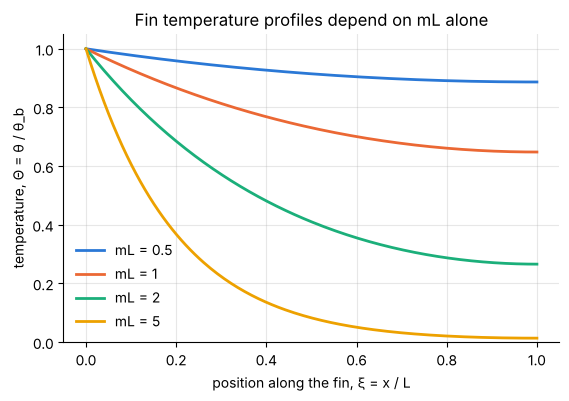

In [16]:
profile_fun = sp.lambdify((xi, mL), profile, "numpy")
xis = np.linspace(0, 1, 200)

fig, ax = plt.subplots()
for value in (0.5, 1, 2, 5):
    ax.plot(xis, profile_fun(xis, value), label=f"mL = {value:g}")
ax.set(xlabel="position along the fin, ξ = x / L", ylabel="temperature, Θ = θ / θ_b", ylim=(0, 1.05),
       title="Fin temperature profiles depend on mL alone")
ax.legend(frameon=False, loc="lower left");

**Answer.** The scaled equation is $\dfrac{d^2\Theta}{d\xi^2} = (mL)^2\,\Theta$, and the single
group is

$$mL = L\sqrt{\frac{hP}{kA_c}} .$$

Five parameters ($h$, $P$, $k$, $A_c$, $L$) collapse into one number. A small $mL$ means
conduction along the fin is strong compared with convection from its surface, so the fin is
nearly isothermal. A large $mL$ means the temperature falls to the surroundings long before the
tip, and the outer part of the fin does little. It is the same group that sets the fin
efficiency $\tanh(mL)/(mL)$.